# 05. Evaluación final

Evaluación del detector publicado (versión v2, fusión V3) sobre la partición de prueba, que no intervino en
ninguna decisión de entrenamiento, calibración ni umbral. Este notebook usa la prueba una sola vez y agrega:

1. Métricas con intervalos de confianza por bootstrap y comparación con la línea base (prueba de McNemar).
2. Curvas ROC y precisión-recall, calibración y distribución del puntaje de riesgo.
3. Análisis por subgrupos con Fairlearn (corpus, longitud, presencia de URL y antigüedad).
4. Workshop 1 de la Semana 5: escenarios de estrés (ruido, ofuscación, información incompleta, rama caída,
   desbalance y cambio de distribución) con un criterio de aceptación fijado de antemano.
5. Ruta española y tabla final de metas SMART.

Se reportan dos umbrales sobre P(phishing):

| Umbral | Origen | Uso |
|---|---|---|
| Validación (D9) | El más bajo con FPR de hasta 1 % en validación | Umbral con el que se eligió el modelo |
| Operativo (D27) | `config.yaml`, elegido con correo corporativo real (Enron, notebook 15) | Umbral desplegado en la API |

**Requisito:** entorno con GPU para la sección 7 (en CPU funciona, pero tarda bastante más).

In [1]:
# Rutas, semillas y módulos del proyecto. En Colab se monta Google Drive: el repositorio
# debe estar copiado en MyDrive/PI_G17/phishing-hibrido-g17 y los datos en MyDrive/PI_G17.
# Las variables de entorno G17_REPO y G17_BASE permiten usar otras ubicaciones.
import os
import sys
from pathlib import Path

try:
    from google.colab import drive

    drive.mount("/content/drive")
    RAIZ_POR_DEFECTO = "/content/drive/MyDrive/PI_G17/phishing-hibrido-g17"
except ImportError:
    RAIZ_POR_DEFECTO = str(Path.cwd().parent)

RAIZ = Path(os.environ.get("G17_REPO", RAIZ_POR_DEFECTO)).resolve()
if not (RAIZ / "src").is_dir():
    raise FileNotFoundError(f"No se encontró el repositorio en {RAIZ}; defina G17_REPO")
sys.path.insert(0, str(RAIZ))

from src.utils import cargar_config, configurar_logging, detectar_entorno, fijar_semillas, ruta_datos
from src.visualizacion import aplicar_estilo, guardar_figura

CONFIG = cargar_config(RAIZ / "config.yaml")
SEMILLA = CONFIG["semilla"]
fijar_semillas(SEMILLA)
configurar_logging("WARNING")
aplicar_estilo()

ENTORNO = detectar_entorno()
BASE = ruta_datos(CONFIG, ENTORNO)
PROCESADOS = BASE / CONFIG["rutas"]["datos_procesados"]
MODELOS = BASE / CONFIG["rutas"]["modelos"]
FIGURAS = RAIZ / "results/figures/05_evaluacion"
METRICAS = RAIZ / "results/metrics"
FIGURAS.mkdir(parents=True, exist_ok=True)
METRICAS.mkdir(parents=True, exist_ok=True)
print(f"Entorno: {ENTORNO} | repositorio: {RAIZ} | datos: {BASE}")

Mounted at /content/drive
Entorno: colab | repositorio: /content/drive/MyDrive/PI_G17/phishing-hibrido-g17 | datos: /content/drive/MyDrive/PI_G17


In [2]:
import importlib.util
import json
import subprocess
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
if importlib.util.find_spec("fairlearn") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "fairlearn==0.13.0"], check=True)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fairlearn.metrics import MetricFrame
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

from src import escenarios
from src import evaluate as ev
from src.model import matriz_meta
from src.visualizacion import COLORES_CLASE, COLORES_SERIE, NOMBRES_CLASE, miles

CLASES = CONFIG["clases"]
PH = 2
PARAMETROS = CONFIG["evaluacion"]
COLUMNAS_P = ["p_legitimo", "p_spam", "p_phishing"]

## 1. Probabilidades de prueba de cada componente

* Línea base: el modelo publicado se aplica al texto de prueba.
* DistilBERT: probabilidades guardadas por `notebooks/experimentos/06_distilbert` (GPU).
* Fusión: el meta-clasificador publicado (`fusion_v1.joblib`) sobre las salidas de las ramas.

In [3]:
datos = pd.read_parquet(PROCESADOS / "emails_v1.parquet",
                        columns=["id", "grupo", "clase", "y", "anio", "sin_url", "len_plano", "split", "texto_modelo"])
prueba = datos[datos["split"] == "test"].reset_index(drop=True)
y = prueba["y"].to_numpy()

baseline = joblib.load(MODELOS / "baseline_tfidf_lr_v1.joblib")
fusion = joblib.load(MODELOS / "fusion_v1.joblib")
UMBRAL_VALIDACION = float(fusion["umbral_fpr1"])
UMBRAL_OPERATIVO = float(CONFIG["fusion"]["umbral_operativo_en"])

p_baseline = baseline.predict_proba(prueba["texto_modelo"].str[: CONFIG["texto"]["max_chars_baseline"]])
bert = prueba[["id"]].merge(pd.read_parquet(PROCESADOS / "text_scores_distilbert_v1.parquet"), on="id", how="left")
if bert[COLUMNAS_P].isna().any().any():
    raise ValueError("Las probabilidades de DistilBERT no cubren toda la prueba")
p_bert = bert[COLUMNAS_P].to_numpy()
ramas_url = prueba[["id"]].merge(pd.read_parquet(PROCESADOS / "url_scores_v1.parquet"), on="id", how="left")
p_fusion = fusion["modelo"].predict_proba(matriz_meta(fusion["variante"], p_bert, p_baseline, ramas_url))

print(f"Correos de prueba: {miles(len(prueba))} | variante: {fusion['variante']} | "
      f"umbral de validación: {UMBRAL_VALIDACION:.4f} | umbral operativo: {UMBRAL_OPERATIVO:.4f}")

Correos de prueba: 8.203 | variante: V3 | umbral de validación: 0.0390 | umbral operativo: 0.8586


**Control de consistencia.** Con el umbral de validación, las métricas deben coincidir con las que registró el
notebook de fusión (`results/metrics/fusion_v1.json`). Una diferencia indicaría que los artefactos de Drive no
son los publicados.

In [4]:
registrado = json.loads((METRICAS / "fusion_v1.json").read_text())["principal"][fusion["variante"]]["test_umbral"]
actual = ev.metricas(y, ev.predecir(p_fusion, UMBRAL_VALIDACION))
consistencia = pd.DataFrame({
    "registrado": {"f1_macro": registrado["f1_macro"], "recall_phishing": registrado["recall"]["phishing"],
                   "fpr_phishing": registrado["fpr_phishing"]},
    "recalculado": {"f1_macro": actual["f1_macro"], "recall_phishing": actual["recall"]["phishing"],
                    "fpr_phishing": actual["fpr_phishing"]}})
consistencia["diferencia"] = (consistencia["recalculado"] - consistencia["registrado"]).round(4)
consistencia

,registrado,recalculado,diferencia
f1_macro,0.9874,0.9874,0.0
recall_phishing,0.9966,0.9966,0.0
fpr_phishing,0.0091,0.0091,0.0


Las tres métricas coinciden exactamente con las registradas: los artefactos leídos son los publicados.

## 2. Métricas con intervalos de confianza

Intervalos al 95 % por bootstrap de percentiles (2.000 remuestreos de correos). El piso de referencia es un
clasificador estratificado que no mira el texto.

In [5]:
dummy = DummyClassifier(strategy="stratified", random_state=SEMILLA).fit(
    np.zeros((int((datos["split"] == "train").sum()), 1)), datos.loc[datos["split"] == "train", "y"])
PREDICCIONES = {
    "Piso (estratificado)": dummy.predict(np.zeros((len(y), 1))),
    "Línea base TF-IDF": p_baseline.argmax(1),
    "DistilBERT": p_bert.argmax(1),
    "Fusión V3, umbral de validación": ev.predecir(p_fusion, UMBRAL_VALIDACION),
    "Fusión V3, umbral operativo": ev.predecir(p_fusion, UMBRAL_OPERATIVO),
}


def recall_phishing(y_real, prediccion):
    positivos = y_real == PH
    return float((prediccion[positivos] == PH).mean()) if positivos.any() else np.nan


def precision_phishing(y_real, prediccion):
    marcados = prediccion == PH
    return float((y_real[marcados] == PH).mean()) if marcados.any() else np.nan


def fpr_phishing(y_real, prediccion):
    negativos = y_real != PH
    return float((prediccion[negativos] == PH).mean()) if negativos.any() else np.nan


def f1_macro(y_real, prediccion):
    return f1_score(y_real, prediccion, average="macro", labels=[0, 1, 2], zero_division=0)


METRICAS_IC = {"F1 macro": f1_macro, "Recall phishing": recall_phishing,
               "Precisión phishing": precision_phishing, "FPR phishing": fpr_phishing}
filas = []
inicio = time.time()
for modelo, prediccion in PREDICCIONES.items():
    fila = {"modelo": modelo}
    for nombre, funcion in METRICAS_IC.items():
        valor, inferior, superior = ev.intervalo_bootstrap(y, prediccion, funcion,
                                                           PARAMETROS["remuestreos_bootstrap"], semilla=SEMILLA)
        fila[nombre] = f"{valor:.4f} [{inferior:.4f}, {superior:.4f}]"
        fila[f"_{nombre}"] = (valor, inferior, superior)
    filas.append(fila)
tabla_metricas = pd.DataFrame(filas).set_index("modelo")
print(f"Bootstrap en {time.time() - inicio:.0f} s")
tabla_metricas[list(METRICAS_IC)]

Bootstrap en 51 s


,F1 macro,Recall phishing,Precisión phishing,FPR phishing
modelo,,,,
Piso (estratificado),"0.3344 [0.3240, 0.3440]","0.1962 [0.1757, 0.2159]","0.1927 [0.1727, 0.2123]","0.1821 [0.1733, 0.1916]"
Línea base TF-IDF,"0.9870 [0.9843, 0.9896]","0.9832 [0.9764, 0.9897]","0.9753 [0.9670, 0.9829]","0.0055 [0.0039, 0.0074]"
DistilBERT,"0.9899 [0.9875, 0.9923]","0.9872 [0.9811, 0.9925]","0.9793 [0.9721, 0.9863]","0.0046 [0.0031, 0.0063]"
"Fusión V3, umbral de validación","0.9874 [0.9846, 0.9900]","0.9966 [0.9934, 0.9993]","0.9605 [0.9505, 0.9699]","0.0091 [0.0069, 0.0114]"
"Fusión V3, umbral operativo","0.9869 [0.9841, 0.9895]","0.9637 [0.9539, 0.9726]","0.9910 [0.9857, 0.9953]","0.0019 [0.0010, 0.0031]"


Con el umbral operativo, la fusión obtiene F1 macro de 0,9869 (IC 0,9841 a 0,9895), recall de phishing de 0,9637
(0,9539 a 0,9726), precisión de 0,9910 y FPR de 0,19 % (0,10 % a 0,31 %). Con el umbral de validación el recall
sube a 0,9966, pero el FPR se multiplica por cinco (0,91 %); en correo corporativo real ese umbral produjo 12,5 %
de falsos positivos (sección 6), y por eso se despliega el operativo.

Los intervalos de F1 de la línea base (0,9870), DistilBERT (0,9899) y la fusión (0,9869) se solapan: en esta
partición, donde los tres superan 0,98, ninguno es claramente superior en exactitud global.

## 3. Comparación con la línea base: prueba de McNemar

La prueba exacta de McNemar compara dos clasificadores sobre los mismos correos usando solo los casos en que
discrepan: `solo_a` son los correos que acierta el primero y falla el segundo, y `solo_b` al revés.

In [6]:
pares = [("Línea base TF-IDF", "Fusión V3, umbral operativo"),
         ("DistilBERT", "Fusión V3, umbral operativo"),
         ("Fusión V3, umbral de validación", "Fusión V3, umbral operativo")]
mcnemar = pd.DataFrame([{"A": a, "B": b, **ev.prueba_mcnemar(y, PREDICCIONES[a], PREDICCIONES[b])} for a, b in pares])
mcnemar

,A,B,solo_a,solo_b,p_valor
0,Línea base TF-IDF,"Fusión V3, umbral operativo",36,39,0.817554
1,DistilBERT,"Fusión V3, umbral operativo",51,33,0.062972
2,"Fusión V3, umbral de validación","Fusión V3, umbral operativo",49,47,0.918778


Ninguna diferencia es significativa al 5 %. Frente a la línea base, la fusión acierta 39 correos que la línea base
falla y falla 36 que la línea base acierta (p = 0,82); frente a DistilBERT hay una tendencia a favor de
DistilBERT (51 frente a 33, p = 0,063). La fusión no mejora la exactitud de tres clases en la partición aleatoria.
Su aporte está en otros dos aspectos medidos:

* **Un puntaje calibrado con umbral ajustable**, que permitió fijar el FPR en correo corporativo (sección 6).
* **Robustez fuera de distribución** (`results/metrics/fusion_v1.json`): con phishing_pot fuera del
  entrenamiento, la fusión V3 detecta el 83,5 % de ese phishing, frente al 68,5 % de la línea base sola (V0) y
  el 73,6 % de DistilBERT solo (V1); con Nigerian Fraud fuera, 94,1 % frente a 91,7 % y 84,8 %.

## 4. Matriz de confusión, curvas y calibración

**Figura 20.** Matriz de confusión de la fusión con el umbral operativo (conteos y porcentaje por fila).

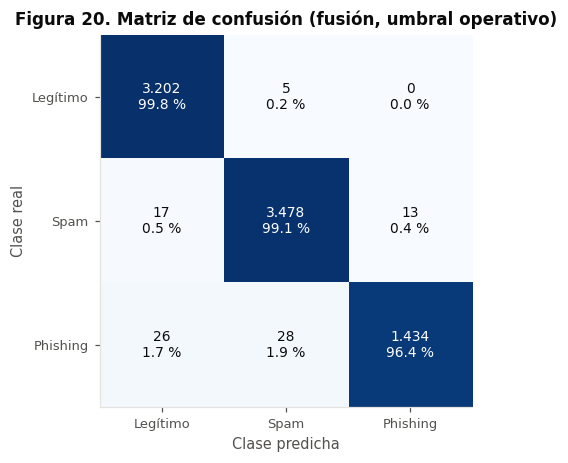

In [7]:
matriz = confusion_matrix(y, PREDICCIONES["Fusión V3, umbral operativo"], labels=[0, 1, 2])
porcentaje = 100 * matriz / matriz.sum(axis=1, keepdims=True)
figura, eje = plt.subplots(figsize=(5.4, 4.4))
eje.imshow(porcentaje, cmap="Blues", vmin=0, vmax=100)
etiquetas = [NOMBRES_CLASE[c] for c in CLASES]
eje.set_xticks(range(3), etiquetas)
eje.set_yticks(range(3), etiquetas)
eje.set_xlabel("Clase predicha")
eje.set_ylabel("Clase real")
for i in range(3):
    for j in range(3):
        eje.text(j, i, f"{miles(matriz[i, j])}\n{porcentaje[i, j]:.1f} %", ha="center", va="center", fontsize=9,
                 color="white" if porcentaje[i, j] > 60 else "#0b0b0b")
eje.grid(False)
eje.set_title("Figura 20. Matriz de confusión (fusión, umbral operativo)")
guardar_figura(figura, FIGURAS / "fig20_matriz_confusion.png")
plt.show()

**Figura 21.** Curvas ROC y precisión-recall de phishing frente al resto para cada componente.

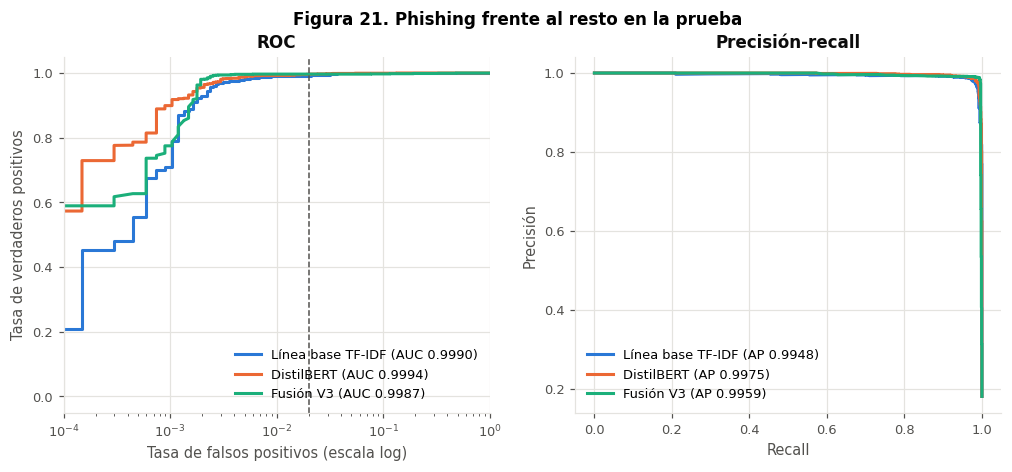

,auc_roc,auc_pr
Línea base TF-IDF,0.99905,0.99484
DistilBERT,0.99943,0.99747
Fusión V3,0.99874,0.99592


In [8]:
es_phishing = (y == PH).astype(int)
PUNTAJES = {"Línea base TF-IDF": p_baseline[:, PH], "DistilBERT": p_bert[:, PH], "Fusión V3": p_fusion[:, PH]}
figura, (eje_roc, eje_pr) = plt.subplots(1, 2, figsize=(11, 4.2))
areas = {}
for k, (nombre, puntaje) in enumerate(PUNTAJES.items()):
    fpr, tpr, _ = roc_curve(es_phishing, puntaje)
    precision, recall, _ = precision_recall_curve(es_phishing, puntaje)
    areas[nombre] = {"auc_roc": round(float(roc_auc_score(es_phishing, puntaje)), 5),
                     "auc_pr": round(float(average_precision_score(es_phishing, puntaje)), 5)}
    eje_roc.plot(fpr, tpr, color=COLORES_SERIE[k], label=f"{nombre} (AUC {areas[nombre]['auc_roc']:.4f})")
    eje_pr.plot(recall, precision, color=COLORES_SERIE[k], label=f"{nombre} (AP {areas[nombre]['auc_pr']:.4f})")
eje_roc.set_xscale("log")
eje_roc.set_xlim(1e-4, 1)
eje_roc.axvline(CONFIG["metas_smart"]["fpr_maximo"], color="#52514e", linestyle="--", linewidth=1)
eje_roc.set_xlabel("Tasa de falsos positivos (escala log)")
eje_roc.set_ylabel("Tasa de verdaderos positivos")
eje_roc.set_title("ROC")
eje_roc.legend(loc="lower right")
eje_pr.set_xlabel("Recall")
eje_pr.set_ylabel("Precisión")
eje_pr.set_title("Precisión-recall")
eje_pr.legend(loc="lower left")
figura.suptitle("Figura 21. Phishing frente al resto en la prueba", fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig21_roc_pr.png")
plt.show()
pd.DataFrame(areas).T

Los tres componentes separan el phishing casi perfectamente (AUC-ROC de 0,9987 o más). La fusión queda
levemente por debajo de DistilBERT en AUC (0,9987 frente a 0,9994), probablemente porque la calibración isotónica
agrupa los puntajes en escalones y pierde resolución para ordenar los casos extremos; a cambio, sus probabilidades son más
fiables, como muestra la figura siguiente.

**Figura 22.** Diagrama de fiabilidad de P(phishing): en un modelo bien calibrado, entre los correos con
probabilidad cercana a 0,8 cerca del 80 % es phishing. La fusión incluye una calibración isotónica ajustada en
validación. Casi todos los correos reciben probabilidades cercanas a 0 o a 1, de modo que los intervalos
intermedios tienen pocos casos: se muestran solo los que tienen al menos 10 correos, con el tamaño del punto
proporcional a su número.

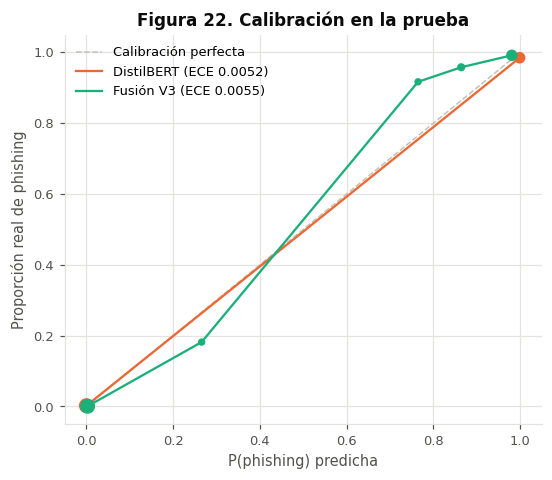

,ece,brier
DistilBERT,0.00516,0.01528
Fusión V3,0.00548,0.01109


In [9]:
figura, eje = plt.subplots(figsize=(5.6, 4.6))
eje.plot([0, 1], [0, 1], color="#c3c2b7", linestyle="--", linewidth=1, label="Calibración perfecta")
bordes = np.linspace(0, 1, 11)
calibracion = {}
for k, (nombre, puntaje) in enumerate([("DistilBERT", p_bert[:, PH]), ("Fusión V3", p_fusion[:, PH])]):
    indice = np.clip(np.digitize(puntaje, bordes) - 1, 0, 9)
    ocupados = [b for b in range(10) if (indice == b).sum() >= 10]
    x = [puntaje[indice == b].mean() for b in ocupados]
    frecuencia = [es_phishing[indice == b].mean() for b in ocupados]
    tamanos = [12 + 8 * np.sqrt((indice == b).sum()) / 10 for b in ocupados]
    calibracion[nombre] = {"ece": ev.ece_phishing(y, puntaje), "brier": ev.brier(y, p_bert if k == 0 else p_fusion)}
    eje.plot(x, frecuencia, "-", color=COLORES_SERIE[k + 1], linewidth=1.5,
             label=f"{nombre} (ECE {calibracion[nombre]['ece']:.4f})")
    eje.scatter(x, frecuencia, s=tamanos, color=COLORES_SERIE[k + 1], zorder=3)
eje.set_xlabel("P(phishing) predicha")
eje.set_ylabel("Proporción real de phishing")
eje.set_title("Figura 22. Calibración en la prueba")
eje.legend(loc="upper left")
guardar_figura(figura, FIGURAS / "fig22_calibracion.png")
plt.show()
pd.DataFrame(calibracion).T

Ambos modelos tienen un error de calibración bajo (ECE cercano a 0,005), y la fusión tiene un puntaje de Brier un
27 % menor (0,0111 frente a 0,0153). En la práctica, el riesgo de 0 a 100 que muestra la interfaz se puede leer
como una probabilidad.

**Figura 23.** Distribución del puntaje de riesgo (0 a 100) por clase real, con los dos umbrales.

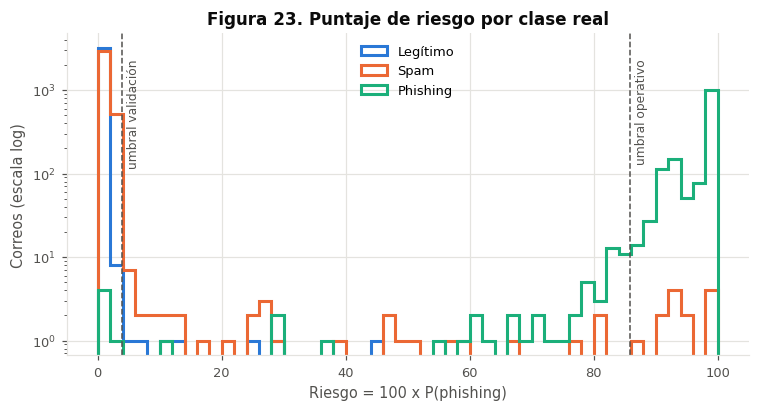

,riesgo_mediano
Legítimo,0.000000
Spam,0.142196
Phishing,99.823884


In [10]:
riesgo = 100 * p_fusion[:, PH]
figura, eje = plt.subplots(figsize=(8, 3.8))
bordes = np.linspace(0, 100, 51)
for k, clase in enumerate(CLASES):
    eje.hist(riesgo[y == k], bins=bordes, histtype="step", linewidth=2, color=COLORES_CLASE[clase],
             label=NOMBRES_CLASE[clase])
eje.set_yscale("log")
for valor, nombre in ((UMBRAL_VALIDACION, "validación"), (UMBRAL_OPERATIVO, "operativo")):
    eje.axvline(100 * valor, color="#52514e", linestyle="--", linewidth=1)
    eje.text(100 * valor + 0.8, eje.get_ylim()[1] * 0.5, f"umbral {nombre}", rotation=90, fontsize=8,
             color="#52514e", va="top")
eje.set_xlabel("Riesgo = 100 x P(phishing)")
eje.set_ylabel("Correos (escala log)")
eje.set_title("Figura 23. Puntaje de riesgo por clase real")
eje.legend(loc="upper center")
guardar_figura(figura, FIGURAS / "fig23_riesgo_por_clase.png")
plt.show()
pd.Series({NOMBRES_CLASE[c]: float(np.median(riesgo[y == k])) for k, c in enumerate(CLASES)}, name="riesgo_mediano")

El riesgo mediano es 0 en legítimo, 0,1 en spam y 99,8 en phishing. Los errores se concentran en la franja
intermedia, que reúne pocos correos.

**Figura 24.** Sensibilidad al umbral: recall de phishing y FPR en la prueba en función del umbral. El umbral no
se elige aquí; la figura muestra el costo de moverlo. En el notebook 15, con correo corporativo real, el umbral
de validación produjo un FPR de 12,5 % y por eso se adoptó el operativo.

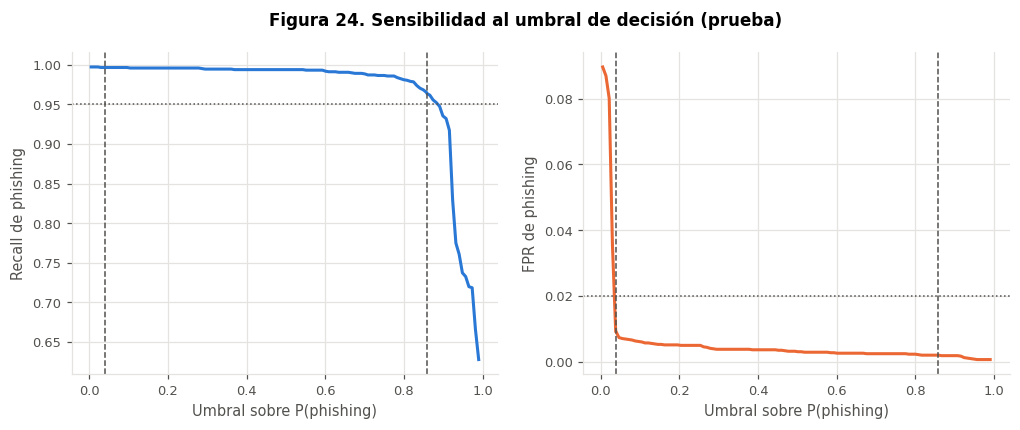

,umbral,recall_phishing,fpr_phishing
5,0.0390,0.9966,0.0091
105,0.8586,0.9637,0.0019


In [11]:
umbrales = np.r_[np.linspace(0.005, 0.99, 120), UMBRAL_VALIDACION, UMBRAL_OPERATIVO]
umbrales.sort()
curva = pd.DataFrame({
    "umbral": umbrales,
    "recall_phishing": [recall_phishing(y, ev.predecir(p_fusion, u)) for u in umbrales],
    "fpr_phishing": [fpr_phishing(y, ev.predecir(p_fusion, u)) for u in umbrales],
})
figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(11, 3.8))
eje_a.plot(curva["umbral"], curva["recall_phishing"], color=COLORES_SERIE[0])
eje_a.axhline(CONFIG["metas_smart"]["recall_phishing"], color="#52514e", linestyle=":", linewidth=1)
eje_a.set_ylabel("Recall de phishing")
eje_b.plot(curva["umbral"], curva["fpr_phishing"], color=COLORES_SERIE[1])
eje_b.axhline(CONFIG["metas_smart"]["fpr_maximo"], color="#52514e", linestyle=":", linewidth=1)
eje_b.set_ylabel("FPR de phishing")
for eje in (eje_a, eje_b):
    for valor in (UMBRAL_VALIDACION, UMBRAL_OPERATIVO):
        eje.axvline(valor, color="#52514e", linestyle="--", linewidth=1)
    eje.set_xlabel("Umbral sobre P(phishing)")
figura.suptitle("Figura 24. Sensibilidad al umbral de decisión (prueba)", fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig24_sensibilidad_umbral.png")
plt.show()
curva[curva["umbral"].isin([UMBRAL_VALIDACION, UMBRAL_OPERATIVO])].round(4)

El recall se mantiene por encima del 98 % hasta un umbral cercano a 0,6 y cae con rapidez por encima de 0,9; el
FPR baja de forma marcada en los primeros valores del umbral y luego es casi plano. El umbral operativo (0,8586)
está en el codo de la curva de recall: conserva el 96,4 % de recall con un FPR de 0,19 %.

## 5. Análisis por subgrupos (Fairlearn)

El detector no usa datos demográficos, pero sí puede rendir distinto según el origen y la forma del correo. Se
mide el recall de phishing y el FPR por subgrupo con `MetricFrame`. Brecha aceptable fijada de antemano:
10 puntos de recall y 2 puntos de FPR entre subgrupos con al menos 50 correos.

* **Corpus:** cada corpus de phishing solo tiene recall; cada corpus de legítimo y spam, solo FPR.
* **Longitud del texto, presencia de URL y antigüedad del correo.**

In [12]:
def tasa_deteccion(y_real, prediccion):
    y_real, prediccion = np.asarray(y_real), np.asarray(prediccion)
    return float(prediccion[y_real == 1].mean()) if (y_real == 1).any() else np.nan


def tasa_falsos_positivos(y_real, prediccion):
    y_real, prediccion = np.asarray(y_real), np.asarray(prediccion)
    return float(prediccion[y_real == 0].mean()) if (y_real == 0).any() else np.nan


def correos(y_real, prediccion):
    return len(y_real)


anio = prueba["anio"]
SUBGRUPOS = {
    "corpus": prueba["grupo"],
    "longitud": pd.cut(prueba["len_plano"], [0, 300, 2000, np.inf], labels=["< 300", "300 a 2.000", "> 2.000"],
                       right=False).astype(str),
    "url": np.where(prueba["sin_url"], "sin URL", "con URL"),
    "antiguedad": np.select([anio.isna(), anio < 2010, anio < 2020], ["sin fecha", "antes de 2010", "2010 a 2019"],
                            "2020 o después"),
}
prediccion_binaria = (PREDICCIONES["Fusión V3, umbral operativo"] == PH).astype(int)
resultados_subgrupos, brechas = {}, {}
for nombre, grupo in SUBGRUPOS.items():
    marco = MetricFrame(metrics={"recall_phishing": tasa_deteccion, "fpr": tasa_falsos_positivos, "correos": correos},
                        y_true=es_phishing, y_pred=prediccion_binaria, sensitive_features=pd.Series(grupo, name=nombre))
    tabla = marco.by_group
    resultados_subgrupos[nombre] = tabla
    suficientes = tabla[tabla["correos"] >= 50]
    brechas[nombre] = {
        "brecha_recall": round(float(suficientes["recall_phishing"].max() - suficientes["recall_phishing"].min()), 4)
        if suficientes["recall_phishing"].notna().sum() > 1 else None,
        "brecha_fpr": round(float(suficientes["fpr"].max() - suficientes["fpr"].min()), 4)
        if suficientes["fpr"].notna().sum() > 1 else None,
    }
    print(f"\n{nombre}")
    display(tabla.round(4))
brechas = pd.DataFrame(brechas).T
brechas["dentro_del_limite"] = [
    (r is None or np.isnan(r) or r <= 0.10) and (f is None or np.isnan(f) or f <= 0.02)
    for r, f in zip(brechas["brecha_recall"].astype(float), brechas["brecha_fpr"].astype(float), strict=True)]
brechas


corpus


,recall_phishing,fpr,correos
corpus,,,
CEAS_08,NaN,0.0005,5844.0
Nigerian_Fraud,0.9452,NaN,493.0
SpamAssasin,NaN,0.0115,871.0
nazario_anual,0.9886,NaN,439.0
phishing_pot,0.9604,NaN,556.0



longitud


,recall_phishing,fpr,correos
longitud,,,
300 a 2.000,0.9860,0.0015,4214.0
< 300,0.9320,0.0000,1909.0
> 2.000,0.9405,0.0052,2080.0



url


,recall_phishing,fpr,correos
url,,,
con URL,0.9704,0.0015,5736.0
sin URL,0.9440,0.0029,2467.0



antiguedad


,recall_phishing,fpr,correos
antiguedad,,,
2010 a 2019,0.9953,0.0000,213.0
2020 o después,0.9665,NaN,775.0
antes de 2010,0.9430,0.0019,7119.0
sin fecha,0.9625,0.0000,96.0


,brecha_recall,brecha_fpr,dentro_del_limite
corpus,0.0434,0.0110,True
longitud,0.0540,0.0052,True
url,0.0264,0.0014,True
antiguedad,0.0523,0.0019,True


Todas las brechas están dentro de los límites fijados (la mayor de recall es de 5,4 puntos, por longitud; la
mayor de FPR, de 1,1 puntos, por corpus). Aun así, hay subgrupos con recall por debajo de la meta de 95 %: los
correos de menos de 300 caracteres (93,2 %), los que no tienen URL (94,4 %), los anteriores a 2010 (94,3 %) y
Nigerian Fraud (94,5 %); estos grupos se solapan en parte, porque Nigerian Fraud es anterior a 2010. El FPR más alto es el de SpamAssassin
(1,15 %, frente a 0,05 % en CEAS_08). Son los casos límite que se documentan como limitaciones del modelo.

**Figura 25.** Recall de phishing (arriba) y FPR (abajo) por subgrupo, con el umbral operativo. Las barras que
faltan corresponden a subgrupos sin casos de esa clase.

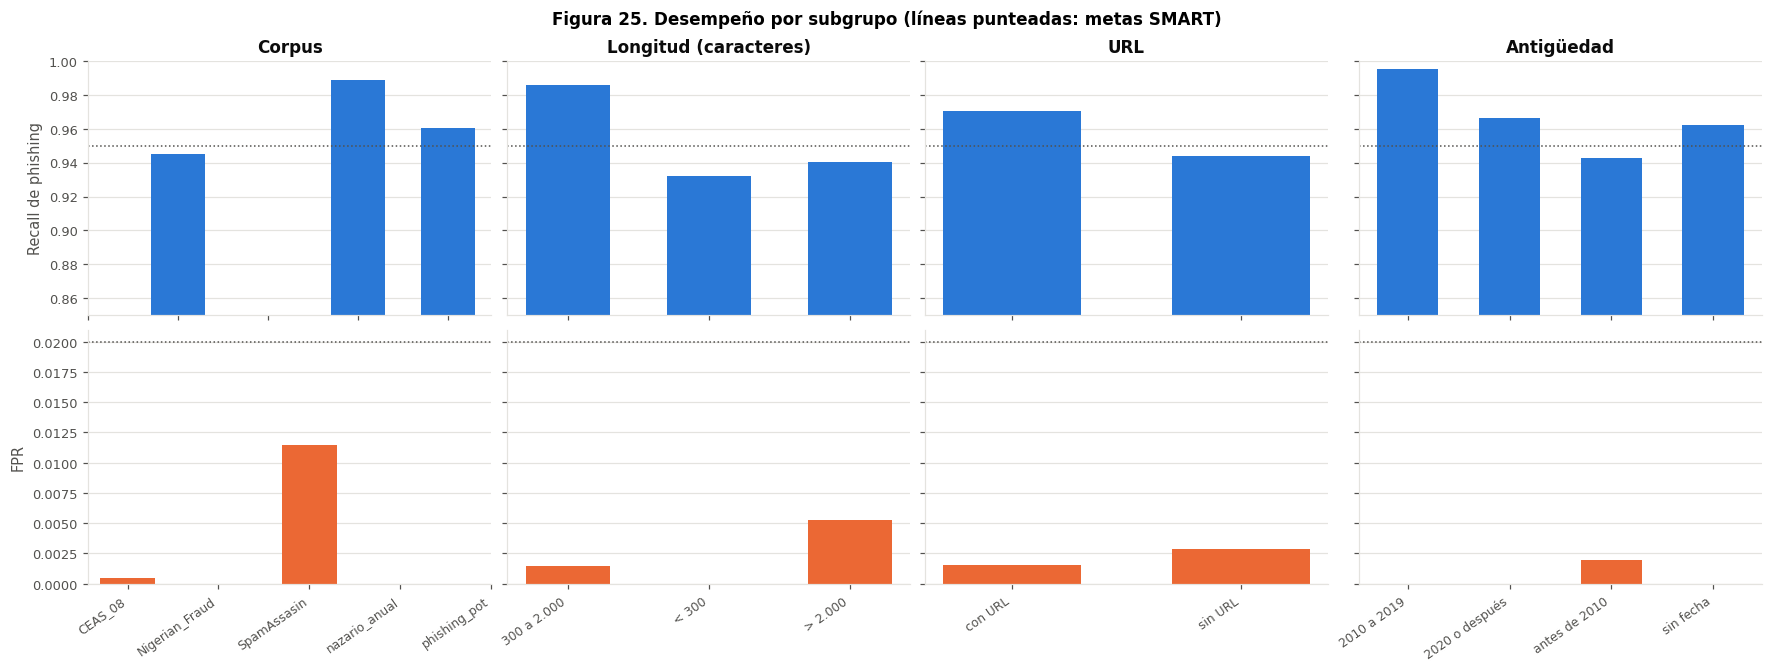

In [13]:
titulos = {"corpus": "Corpus", "longitud": "Longitud (caracteres)", "url": "URL", "antiguedad": "Antigüedad"}
figura, ejes = plt.subplots(2, len(SUBGRUPOS), figsize=(4 * len(SUBGRUPOS), 6), sharey="row",
                            layout="constrained")
for columna, (nombre, tabla) in enumerate(resultados_subgrupos.items()):
    posiciones = np.arange(len(tabla))
    ejes[0, columna].bar(posiciones, tabla["recall_phishing"], color=COLORES_SERIE[0], width=0.6)
    ejes[1, columna].bar(posiciones, tabla["fpr"], color=COLORES_SERIE[1], width=0.6)
    ejes[0, columna].set_title(titulos[nombre])
    ejes[0, columna].set_xticks(posiciones, [])
    ejes[1, columna].set_xticks(posiciones, tabla.index, rotation=35, ha="right", fontsize=8)
    for fila in range(2):
        ejes[fila, columna].grid(axis="x", visible=False)
ejes[0, 0].set_ylim(0.85, 1.0)
ejes[0, 0].set_ylabel("Recall de phishing")
ejes[1, 0].set_ylabel("FPR")
for columna in range(len(SUBGRUPOS)):
    ejes[0, columna].axhline(CONFIG["metas_smart"]["recall_phishing"], color="#52514e", linestyle=":", linewidth=1)
    ejes[1, columna].axhline(CONFIG["metas_smart"]["fpr_maximo"], color="#52514e", linestyle=":", linewidth=1)
figura.suptitle("Figura 25. Desempeño por subgrupo (líneas punteadas: metas SMART)", fontweight="bold",
                fontsize=11)
guardar_figura(figura, FIGURAS / "fig25_subgrupos.png")
plt.show()

## 6. Validación en contextos reales: correo corporativo y español

Resultados de las validaciones externas ya ejecutadas, que miden el cambio de distribución más relevante para
el despliegue:

* **Correo corporativo (Enron):** 2.000 correos legítimos de una empresa real, que el modelo nunca vio
  (`notebooks/experimentos/15_fpr_correo_corporativo`). El umbral operativo se eligió en una mitad y se reporta
  en la otra.
* **Español nativo:** la prueba de SpaPhish y SpearPhishMX se recalcula aquí con la ruta española publicada.

In [14]:
enron = json.loads((METRICAS / "fpr_enron_v1.json").read_text())
externa = pd.DataFrame({
    "umbral de validación": enron["actual"],
    "umbral operativo": enron["umbral_operativo_A"],
}).T[["umbral", "FPR_enron_B_pct", "IC95_B", "recall_test_phishing_pct"]]

espanol = pd.read_parquet(PROCESADOS / "emails_es_v2.parquet", columns=["id", "grupo", "clase", "split"])
espanol = espanol[espanol["grupo"].isin(["SpaPhish", "SpearPhishMX"]) & (espanol["split"] == "test")]
espanol = espanol.merge(pd.read_parquet(PROCESADOS / "text_scores_multi_es_v1.parquet")[["id", *COLUMNAS_P]], on="id")
fusion_es = joblib.load(MODELOS / "fusion_es_v1.joblib")
p_es = fusion_es["modelo"].predict_proba(np.log(np.clip(espanol[COLUMNAS_P].to_numpy(), 1e-6, 1.0)))[:, 1]
espanol["phishing_predicho"] = p_es >= fusion_es["umbral_fpr1"]
espanol["es_phishing"] = espanol["clase"] == "phishing"


def resumen_binario(tabla):
    positivos, negativos = tabla[tabla["es_phishing"]], tabla[~tabla["es_phishing"]]
    tp, fp = int(positivos["phishing_predicho"].sum()), int(negativos["phishing_predicho"].sum())
    recall_ic = ev.intervalo_wilson(tp, len(positivos))
    fpr_ic = ev.intervalo_wilson(fp, len(negativos))
    return {"correos": len(tabla), "recall_phishing": round(tp / max(len(positivos), 1), 4),
            "recall_ic95": [round(v, 4) for v in recall_ic], "fpr": round(fp / max(len(negativos), 1), 4),
            "fpr_ic95": [round(v, 4) for v in fpr_ic]}


ruta_espanola = {"total": resumen_binario(espanol),
                 **{fuente: resumen_binario(tabla) for fuente, tabla in espanol.groupby("grupo")}}
display(externa)
pd.DataFrame(ruta_espanola).T

,umbral,FPR_enron_B_pct,IC95_B,recall_test_phishing_pct
umbral de validación,0.039,12.5,"[10.6, 14.7]",99.73
umbral operativo,0.8586,1.3,"[0.8, 2.2]",95.97


,correos,recall_phishing,recall_ic95,fpr,fpr_ic95
total,641,0.9354,"[0.9064, 0.9559]",0.0354,"[0.0188, 0.066]"
SpaPhish,202,0.8972,"[0.8252, 0.9416]",0.0947,"[0.0506, 0.1703]"
SpearPhishMX,439,0.95,"[0.9178, 0.97]",0.0,"[0.0, 0.0236]"


En inglés, el umbral operativo cumple la meta de FPR en correo corporativo (1,3 %, IC 0,8 % a 2,2 %), mientras que
el de validación no (12,5 %). En español nativo, la ruta detecta el 93,5 % del phishing (IC 90,6 % a 95,6 %) con
un FPR de 3,5 % (1,9 % a 6,6 %), por encima de la meta. El exceso viene de SpaPhish (9,5 % de FPR sobre 95
correos legítimos); en SpearPhishMX no hubo falsos positivos. En la revisión manual hecha para el KPI de triaje
se vieron correos de SpaPhish etiquetados como legítimos que parecían suplantaciones, así que parte de esos
falsos positivos podría ser ruido de etiqueta; no se verificó de forma sistemática.

## 7. Workshop 1: simulación de escenarios críticos

**Pregunta guía:** ¿hasta qué nivel de perturbación el detector sigue siendo útil?

**Método.** Sobre una muestra estratificada de la prueba se aplica cada perturbación al texto de entrada, se
recalculan DistilBERT, la línea base y la fusión, y se compara con la misma muestra sin perturbar. Las
perturbaciones aleatorias se repiten con semillas distintas y se promedian. Se usa el umbral operativo.

**Criterio de aceptación (fijado antes de ver los resultados):** el escenario pasa si el recall de phishing cae
como máximo 5 puntos respecto de la referencia (el mismo margen del workshop) y el FPR no supera la meta SMART
de 2 %. El recall se mide sobre la misma muestra sin perturbar, así que la caída aísla el efecto del escenario.

| Escenario | Qué simula | Implementación |
|---|---|---|
| A. Ruido | Errores tipográficos | `escenarios.ruido_caracteres` al 2 %, 5 % y 10 % de las letras |
| B. Ofuscación | Evasión de filtros por palabra clave | `escenarios.ofuscar_palabras_sensibles` (p@55w0rd) |
| C. Información incompleta | Vista previa o correo cortado | `escenarios.truncar` a 300 y 1.000 caracteres |
| D. Rama caída | La rama URL no responde | Bloque URL en valor neutro, texto intacto |
| E. Sin enlaces | Phishing por adjunto o código QR | `escenarios.quitar_enlaces` y rama URL neutra |
| F. Desbalance | Prevalencia real de phishing más baja | `escenarios.remuestreo_prevalencia` al 10 %, 5 % y 1 % |
| G. Cambio de distribución | Corpus, periodo o idioma no vistos | Pliegues fuera de distribución, Enron y español |

In [15]:
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer
from transformers.utils import logging as registro_transformers

registro_transformers.set_verbosity_error()
registro_transformers.disable_progress_bar()
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
tokenizador = AutoTokenizer.from_pretrained(MODELOS / "distilbert_v1")
modelo_bert = AutoModelForSequenceClassification.from_pretrained(MODELOS / "distilbert_v1").to(DISPOSITIVO).eval()


@torch.no_grad()
def probabilidades_bert(textos, lote=64):
    salida = []
    for inicio in range(0, len(textos), lote):
        entrada = tokenizador(list(textos[inicio:inicio + lote]), truncation=True, padding=True,
                              max_length=CONFIG["texto"]["max_len_distilbert"], return_tensors="pt").to(DISPOSITIVO)
        salida.append(torch.softmax(modelo_bert(**entrada).logits.float(), -1).cpu().numpy())
    return np.concatenate(salida)


def puntuar(textos, ramas):
    """Probabilidades de la fusión para textos de modelo y bloque URL dados."""
    textos = pd.Series(textos)
    p_texto = probabilidades_bert(textos.tolist())
    p_base = baseline.predict_proba(textos.str[: CONFIG["texto"]["max_chars_baseline"]])
    return fusion["modelo"].predict_proba(matriz_meta(fusion["variante"], p_texto, p_base, ramas)), p_texto


def metricas_escenario(y_real, probabilidades):
    prediccion = ev.predecir(probabilidades, UMBRAL_OPERATIVO)
    return {"recall": recall_phishing(y_real, prediccion), "precision": precision_phishing(y_real, prediccion),
            "fpr": fpr_phishing(y_real, prediccion), "f1_macro": f1_macro(y_real, prediccion),
            "accuracy": float((prediccion == y_real).mean())}


fraccion = min(1.0, PARAMETROS["muestra_estres"] / len(prueba))
muestra = prueba.groupby(["clase", "grupo"]).sample(frac=fraccion, random_state=SEMILLA).reset_index(drop=True)
y_muestra = muestra["y"].to_numpy()
ramas_muestra = muestra[["id"]].merge(pd.read_parquet(PROCESADOS / "url_scores_v1.parquet"), on="id", how="left")
ramas_neutras = ramas_muestra.assign(url_b_max=np.nan, url_b_media=np.nan, n_urls_eval=0)

inicio = time.time()
p_referencia, p_texto_referencia = puntuar(muestra["texto_modelo"], ramas_muestra)
guardadas = muestra[["id"]].merge(pd.read_parquet(PROCESADOS / "text_scores_distilbert_v1.parquet"), on="id")
diferencia_bert = float(np.abs(p_texto_referencia - guardadas[COLUMNAS_P].to_numpy()).max())
print(f"Muestra: {miles(len(muestra))} correos en {DISPOSITIVO} ({time.time() - inicio:.0f} s por escenario)")
print(f"Diferencia máxima con las probabilidades guardadas de DistilBERT: {diferencia_bert:.4f}")
resumen_estres = [{"escenario": "Referencia", "nivel": "sin perturbar",
                   **metricas_escenario(y_muestra, p_referencia)}]

Muestra: 2.001 correos en cuda (20 s por escenario)
Diferencia máxima con las probabilidades guardadas de DistilBERT: 0.0017


La diferencia con las probabilidades guardadas se debe a que en el entrenamiento la inferencia se hizo en media
precisión (fp16) y aquí en precisión simple; debe ser pequeña frente a la distancia al umbral.

In [16]:
def escenario_texto(nombre, nivel, transformar, ramas=ramas_muestra, repeticiones=1):
    resultados = []
    for repeticion in range(repeticiones):
        generador = np.random.default_rng(SEMILLA + repeticion)
        textos = [transformar(texto, generador) for texto in muestra["texto_modelo"]]
        probabilidades, _ = puntuar(textos, ramas)
        resultados.append(metricas_escenario(y_muestra, probabilidades))
    resumen_estres.append({"escenario": nombre, "nivel": nivel, **pd.DataFrame(resultados).mean().to_dict()})


inicio = time.time()
for tasa in (0.02, 0.05, 0.10):
    escenario_texto("A. Ruido", f"{int(100 * tasa)} % de letras",
                    lambda t, g, tasa=tasa: escenarios.ruido_caracteres(t, tasa, g),
                    repeticiones=PARAMETROS["repeticiones"])
escenario_texto("B. Ofuscación", "palabras sensibles", lambda t, g: escenarios.ofuscar_palabras_sensibles(t))
for limite in (1000, 300):
    escenario_texto("C. Información incompleta", f"{limite} caracteres",
                    lambda t, g, n=limite: escenarios.truncar(t, n))
escenario_texto("D. Rama URL caída", "bloque URL neutro", lambda t, g: t, ramas=ramas_neutras)
escenario_texto("E. Sin enlaces", "sin URL en texto ni rama", lambda t, g: escenarios.quitar_enlaces(t),
                ramas=ramas_neutras)
print(f"Escenarios de texto en {(time.time() - inicio) / 60:.1f} min")

Escenarios de texto en 5.0 min


**Escenario F, desbalance.** El modelo no cambia; cambia la población. Se conserva todo el phishing de la prueba
completa y se remuestrean los demás correos hasta la prevalencia indicada (10 repeticiones).

In [17]:
for prevalencia in (0.10, 0.05, 0.01):
    resultados = []
    for repeticion in range(10):
        indices = escenarios.remuestreo_prevalencia(y, prevalencia, np.random.default_rng(SEMILLA + repeticion))
        resultados.append(metricas_escenario(y[indices], p_fusion[indices]))
    resumen_estres.append({"escenario": "F. Desbalance", "nivel": f"{round(100 * prevalencia)} % de phishing",
                           **pd.DataFrame(resultados).mean().to_dict()})

**Escenario G, cambio de distribución.** Se toman los resultados ya medidos con la fusión V3 cuando un corpus o
un periodo completo queda fuera del entrenamiento (`results/metrics/fusion_v1.json`), el correo corporativo y
el español nativo.

In [18]:
fuera = json.loads((METRICAS / "fusion_v1.json").read_text())["fuera_de_distribucion"]
for pliegue, valores in fuera.items():
    if isinstance(valores, dict) and fusion["variante"] in valores:
        v = valores[fusion["variante"]]
        resumen_estres.append({"escenario": "G. Cambio de distribución", "nivel": pliegue,
                               "recall": v["recall_phishing_fuera"], "fpr": v["fpr_phishing_test"],
                               "f1_macro": v["f1_test"]})
resumen_estres.append({"escenario": "G. Cambio de distribución", "nivel": "correo corporativo (Enron)",
                       "recall": enron["umbral_operativo_A"]["recall_test_phishing_pct"] / 100,
                       "fpr": enron["umbral_operativo_A"]["FPR_enron_B_pct"] / 100})
resumen_estres.append({"escenario": "G. Cambio de distribución", "nivel": "español nativo",
                       "recall": ruta_espanola["total"]["recall_phishing"], "fpr": ruta_espanola["total"]["fpr"]})

estres = pd.DataFrame(resumen_estres)
recall_referencia = estres.loc[0, "recall"]
estres["caida_recall"] = recall_referencia - estres["recall"]
estres["veredicto"] = np.where((estres["caida_recall"] <= PARAMETROS["caida_recall_maxima"])
                               & (estres["fpr"] <= CONFIG["metas_smart"]["fpr_maximo"]), "OK", "FALLA")
columnas = ["escenario", "nivel", "recall", "precision", "fpr", "f1_macro", "accuracy", "caida_recall", "veredicto"]
estres[columnas].round(4)

,escenario,nivel,recall,precision,fpr,f1_macro,accuracy,caida_recall,veredicto
0,Referencia,sin perturbar,0.9587,0.9886,0.0024,0.9861,0.9890,0.0000,OK
1,A. Ruido,2 % de letras,0.9532,0.9876,0.0026,0.9847,0.9880,0.0055,OK
2,A. Ruido,5 % de letras,0.9532,0.9867,0.0028,0.9844,0.9878,0.0055,OK
3,A. Ruido,10 % de letras,0.9366,0.9855,0.0031,0.9790,0.9832,0.0220,OK
4,B. Ofuscación,palabras sensibles,0.9504,0.9885,0.0024,0.9840,0.9875,0.0083,OK
5,C. Información incompleta,1000 caracteres,0.9614,0.9887,0.0024,0.9864,0.9890,-0.0028,OK
6,C. Información incompleta,300 caracteres,0.9008,0.9879,0.0024,0.9703,0.9770,0.0579,FALLA
7,D. Rama URL caída,bloque URL neutro,0.9091,0.9910,0.0018,0.9742,0.9805,0.0496,OK
8,E. Sin enlaces,sin URL en texto ni rama,0.9201,0.9911,0.0018,0.9766,0.9820,0.0386,OK
9,F. Desbalance,10 % de phishing,0.9637,0.9805,0.0021,0.9864,0.9914,-0.0050,OK


En el escenario G, los pliegues fuera de distribución vienen de `07_fusion` y usan el umbral de validación de cada
pliegue; las filas de correo corporativo y español muestran el recall en la prueba inglesa y en la española,
respectivamente, con el FPR medido en esos correos.

**Figura 26.** Recall y FPR de phishing por escenario. La línea punteada vertical marca el recall mínimo
aceptable (referencia menos 5 puntos) y la meta de FPR.

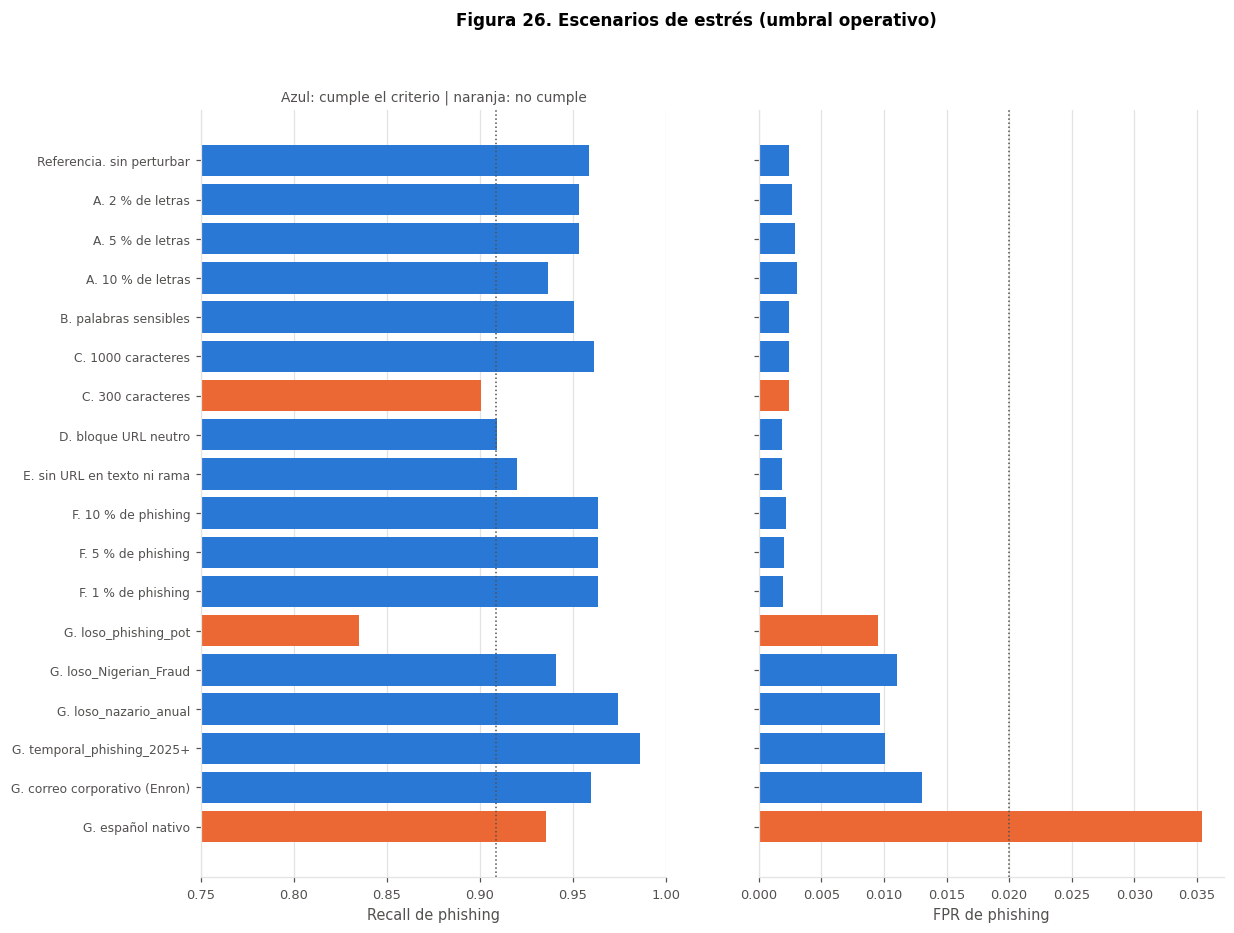

In [19]:
figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(12, 0.42 * len(estres) + 1.5), sharey=True)
etiquetas = (estres["escenario"].str.split(".").str[0] + ". " + estres["nivel"]).tolist()
posiciones = np.arange(len(estres))[::-1]
colores = [COLORES_SERIE[0] if v == "OK" else COLORES_SERIE[1] for v in estres["veredicto"]]
eje_a.barh(posiciones, estres["recall"], color=colores)
eje_a.axvline(recall_referencia - PARAMETROS["caida_recall_maxima"], color="#52514e", linestyle=":", linewidth=1)
eje_a.set_xlim(0.75, 1.0)
eje_a.set_xlabel("Recall de phishing")
eje_a.set_yticks(posiciones, etiquetas, fontsize=8)
eje_b.barh(posiciones, estres["fpr"], color=colores)
eje_b.axvline(CONFIG["metas_smart"]["fpr_maximo"], color="#52514e", linestyle=":", linewidth=1)
eje_b.set_xlabel("FPR de phishing")
for eje in (eje_a, eje_b):
    eje.grid(axis="y", visible=False)
eje_a.set_title("Azul: cumple el criterio | naranja: no cumple", fontsize=9, fontweight="normal", color="#52514e")
figura.suptitle("Figura 26. Escenarios de estrés (umbral operativo)", fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig26_escenarios_estres.png")
plt.show()

**Lectura del Workshop 1.**

1. **Qué degrada más el recall.** Un corpus de phishing nunca visto (phishing_pot fuera: 83,5 %) y, entre las
   perturbaciones, el texto truncado a 300 caracteres (una caída de alrededor de 6 puntos). Quitar la rama URL
   resta alrededor de 5 puntos, lo que mide su aporte con el umbral operativo.
2. **Qué degrada más la precisión.** El desbalance: con 1 % de phishing la precisión baja a alrededor de 84 %
   aunque el recall no cambia.
3. **Por qué engaña la exactitud.** En ese mismo escenario la exactitud sube a más de 99 %, porque casi todos los
   correos son legítimos o spam y se clasifican bien; por eso el proyecto reporta recall, FPR y precisión.
4. **Robustez.** El ruido tipográfico (hasta 10 % de las letras) y la ofuscación de palabras sensibles restan
   a lo sumo unos 2 puntos: el detector no depende de palabras clave exactas.
5. **Escenarios que fallan y mitigación.**
   * *Correos muy cortos:* la interfaz advierte cuando el texto es breve y recomienda revisión manual.
   * *Campañas nuevas:* reentrenamiento periódico con phishing reciente y monitoreo de la proporción de correos
     con riesgo intermedio como señal de deriva.
   * *Español:* el FPR supera la meta; se mantiene la revisión manual de los positivos en español y se documenta
     como limitación.

## 8. Metas SMART

Tabla final con la fuente de cada valor. Lo que no se midió sobre una muestra suficiente se marca como
estimación.

In [20]:
kpi = json.loads((METRICAS / "kpi" / "kpi_resumen.json").read_text())
triaje = json.loads((METRICAS / "kpi" / "triaje_resumen.json").read_text())
operativo = tabla_metricas.loc["Fusión V3, umbral operativo"]
metas = CONFIG["metas_smart"]
enron_operativo = enron["umbral_operativo_A"]


def fila(meta, resultado, fuente, cumple):
    return {"meta": meta, "resultado": resultado, "fuente": fuente, "cumple": bool(cumple)}


smart = pd.DataFrame([
    fila("F1 macro >= 0,90", operativo["F1 macro"], "prueba, umbral operativo",
         operativo["_F1 macro"][0] >= metas["f1_macro"]),
    fila("Recall de phishing >= 95 %", operativo["Recall phishing"], "prueba, umbral operativo",
         operativo["_Recall phishing"][0] >= metas["recall_phishing"]),
    fila("FPR <= 2 % (inglés, correo corporativo)",
         f"{enron_operativo['FPR_enron_B_pct']} % IC {enron_operativo['IC95_B']}", "Enron, notebook 15",
         enron_operativo["FPR_enron_B_pct"] / 100 <= metas["fpr_maximo"]),
    fila("FPR <= 2 % (español nativo)", f"{100 * ruta_espanola['total']['fpr']:.1f} %", "prueba española",
         ruta_espanola["total"]["fpr"] <= metas["fpr_maximo"]),
    fila("Latencia < 1 s", f"p95 {kpi['latencia_ms_p95']} ms de punta a punta", "lote KPI, 200 correos",
         kpi["latencia_ms_p95"] < metas["latencia_ms"]),
    fila("Alertas integradas > 90 %", f"{kpi['kpi_alertas_integradas_pct']} %", "lote KPI, IRIS y Wazuh",
         kpi["kpi_alertas_integradas_pct"] / 100 > metas["alertas_integradas"]),
    fila("Reducción del triaje N1 >= 40 %",
         f"{triaje['reduccion_tiempo_pct']} % IC {triaje['ic95_reduccion_pct']} (estimación)",
         "20 correos, 2 analistas", triaje["reduccion_tiempo_pct"] / 100 >= metas["reduccion_triaje"]),
])
smart

,meta,resultado,fuente,cumple
0,"F1 macro >= 0,90","0.9869 [0.9841, 0.9895]","prueba, umbral operativo",True
1,Recall de phishing >= 95 %,"0.9637 [0.9539, 0.9726]","prueba, umbral operativo",True
2,"FPR <= 2 % (inglés, correo corporativo)","1.3 % IC [0.8, 2.2]","Enron, notebook 15",True
3,FPR <= 2 % (español nativo),3.5 %,prueba española,False
4,Latencia < 1 s,p95 275 ms de punta a punta,"lote KPI, 200 correos",True
5,Alertas integradas > 90 %,100.0 %,"lote KPI, IRIS y Wazuh",True
6,Reducción del triaje N1 >= 40 %,"32.4 % IC [-25.2, 68.0] (estimación)","20 correos, 2 analistas",False


Se cumplen cinco de las siete metas. No se cumplen el FPR en español (3,5 %) y la reducción del tiempo de triaje
(32,4 %, una estimación con 20 correos y dos analistas cuyo intervalo incluye valores negativos). El recall
medido aquí (96,4 %) corresponde a los componentes evaluados por lotes; con el detector de producción completo,
que además enruta por idioma, el notebook 15 midió 95,97 % en la misma prueba.

In [21]:
resumen = {
    "umbrales": {"validacion": UMBRAL_VALIDACION, "operativo": UMBRAL_OPERATIVO},
    "consistencia_con_fusion_v1": consistencia.to_dict(orient="index"),
    "metricas_ic95": {m: {k: tabla_metricas.loc[m, f"_{k}"] for k in METRICAS_IC} for m in tabla_metricas.index},
    "mcnemar": mcnemar.to_dict(orient="records"),
    "areas": areas,
    "calibracion": calibracion,
    "subgrupos": {k: v.round(4).reset_index().to_dict(orient="records") for k, v in resultados_subgrupos.items()},
    "brechas_subgrupos": brechas.to_dict(orient="index"),
    "ruta_espanola": ruta_espanola,
    "estres": {"muestra": int(len(muestra)), "diferencia_bert_guardado": round(diferencia_bert, 5),
               "escenarios": estres[columnas].round(4).to_dict(orient="records")},
    "smart": smart.to_dict(orient="records"),
}
(METRICAS / "evaluacion_final.json").write_text(json.dumps(resumen, indent=1, ensure_ascii=False, default=str),
                                                encoding="utf-8")
print(json.dumps({"smart": resumen["smart"], "mcnemar": resumen["mcnemar"]}, indent=1, ensure_ascii=False,
                 default=str))

{
 "smart": [
  {
   "meta": "F1 macro >= 0,90",
   "resultado": "0.9869 [0.9841, 0.9895]",
   "fuente": "prueba, umbral operativo",
   "cumple": true
  },
  {
   "meta": "Recall de phishing >= 95 %",
   "resultado": "0.9637 [0.9539, 0.9726]",
   "fuente": "prueba, umbral operativo",
   "cumple": true
  },
  {
   "meta": "FPR <= 2 % (inglés, correo corporativo)",
   "resultado": "1.3 % IC [0.8, 2.2]",
   "fuente": "Enron, notebook 15",
   "cumple": true
  },
  {
   "meta": "FPR <= 2 % (español nativo)",
   "resultado": "3.5 %",
   "fuente": "prueba española",
   "cumple": false
  },
  {
   "meta": "Latencia < 1 s",
   "resultado": "p95 275 ms de punta a punta",
   "fuente": "lote KPI, 200 correos",
   "cumple": true
  },
  {
   "meta": "Alertas integradas > 90 %",
   "resultado": "100.0 %",
   "fuente": "lote KPI, IRIS y Wazuh",
   "cumple": true
  },
  {
   "meta": "Reducción del triaje N1 >= 40 %",
   "resultado": "32.4 % IC [-25.2, 68.0] (estimación)",
   "fuente": "20 correos, 2 an